## Analysing the dataset to extract insights and information about data.

In [26]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns


In [27]:
data = pd.read_csv(r'..\Datasets\Raw\Food delivery.csv')

In [28]:
data.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [29]:
# Cell 3: Get the shape (number of rows and columns) of the dataset
data.shape

(45593, 20)

In [30]:
# Cell 4: View the statistical summary of numerical columns
data.describe()

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition
count,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000
mean,17.017729,70.231332,17.465186,70.845702,1.023359
std,8.185109,22.883647,7.335122,21.118812,0.839065
min,-30.905562,-88.366217,0.010000,0.010000,0.000000
25%,12.933284,73.170000,12.988453,73.280000,0.000000
50%,18.546947,75.898497,18.633934,76.002574,1.000000
75%,22.728163,78.044095,22.785049,78.107044,2.000000
max,30.914057,88.433452,31.054057,88.563452,3.000000


In [31]:
data.describe(include='str')

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
count,45593,45593,45593,45593,45593,45593,45593,45593,45593,45593,45593,45593,45593,45593,45593
unique,45593,1320,23,29,44,177,193,7,5,4,4,5,3,4,45
top,0x4607,JAPRES11DEL02,35,4.8,15-03-2022,NaN,21:30:00,conditions Fog,Low,Snack,motorcycle,1,No,Metropolitian,(min) 26
freq,1,67,2262,7148,1192,1731,496,7654,15477,11533,26435,28159,44469,34093,2123


In [32]:
# Cell 5: View a concise summary of the dataframe (data types, non-null counts, memory usage)
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  str    
 1   Delivery_person_ID           45593 non-null  str    
 2   Delivery_person_Age          45593 non-null  str    
 3   Delivery_person_Ratings      45593 non-null  str    
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  str    
 9   Time_Orderd                  45593 non-null  str    
 10  Time_Order_picked            45593 non-null  str    
 11  Weatherconditions            45593 non-null  str    
 12  Road_traffic_density         45593 non-null  str    
 13  Vehicle_condition          

In [33]:
# Cell 6: Check for null (missing) values in each column
data.isnull().sum()

ID                             0
Delivery_person_ID             0
Delivery_person_Age            0
Delivery_person_Ratings        0
Restaurant_latitude            0
Restaurant_longitude           0
Delivery_location_latitude     0
Delivery_location_longitude    0
Order_Date                     0
Time_Orderd                    0
Time_Order_picked              0
Weatherconditions              0
Road_traffic_density           0
Vehicle_condition              0
Type_of_order                  0
Type_of_vehicle                0
multiple_deliveries            0
Festival                       0
City                           0
Time_taken(min)                0
dtype: int64

In [34]:
# Cell 7: Check for the total number of duplicate rows
data.duplicated().sum()

np.int64(0)

#### As we analyzed above there is no null and no duplicate value means the data is clean but we can only check numerical values through this.
#### Lets check relation between features.

<Axes: xlabel='Time_taken(min)', ylabel='Count'>

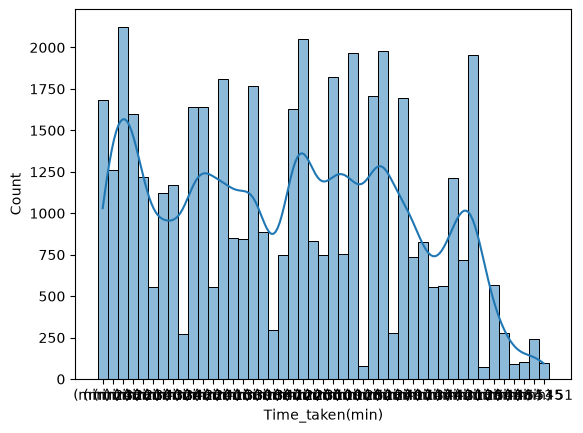

In [35]:
plt.Figure(figsize=(8,26))
sns.histplot(x='Time_taken(min)',data=data,kde=True)


<Axes: >

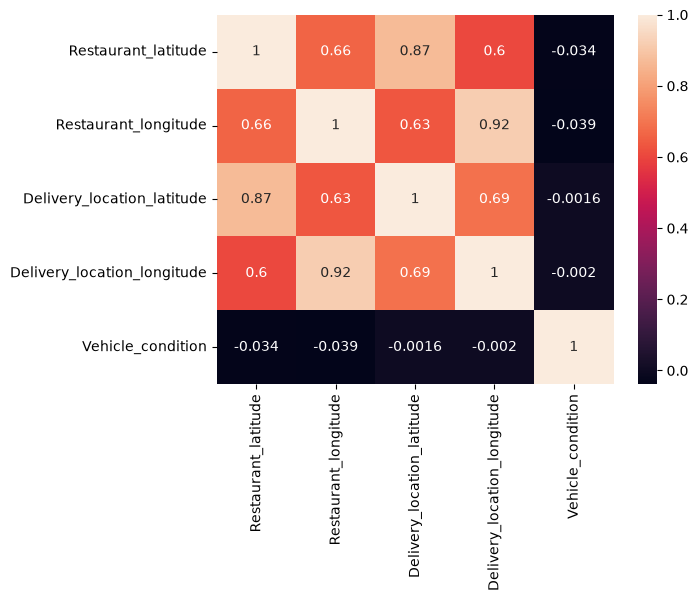

In [36]:
sns.heatmap(data.corr(numeric_only=True),annot=True)


In [37]:
data['Road_traffic_density'].unique()

<StringArray>
['High ', 'Jam ', 'Low ', 'Medium ', 'NaN ']
Length: 5, dtype: str

<Axes: xlabel='Road_traffic_density', ylabel='Time_taken(min)'>

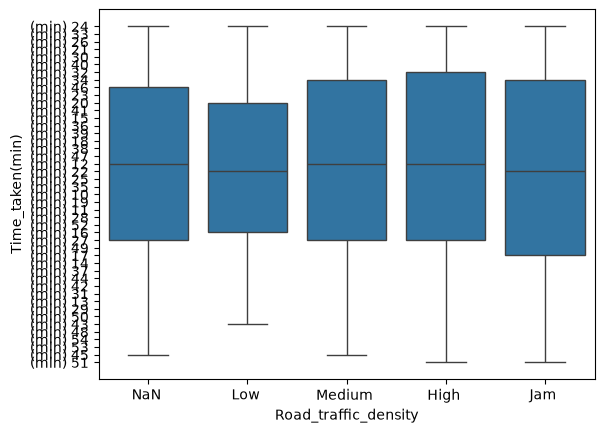

In [38]:
order = [ 'NaN ', 'Low ', 'Medium ','High ', 'Jam ']
sns.boxplot(x='Road_traffic_density',y='Time_taken(min)',data=data,order=order)

<Axes: xlabel='Restaurant_latitude', ylabel='Time_taken(min)'>

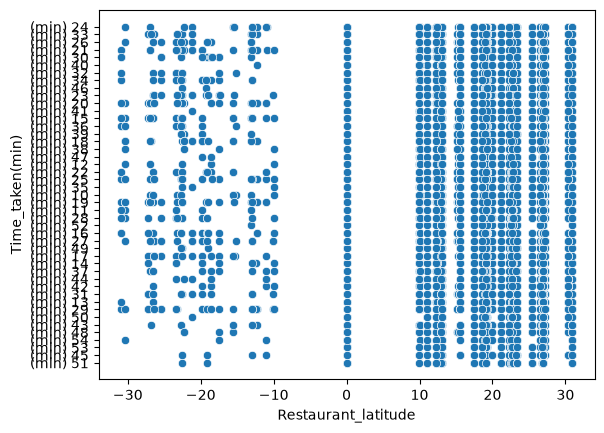

In [39]:
sns.scatterplot(x='Restaurant_latitude',y='Time_taken(min)',data=data)

<Axes: xlabel='Restaurant_longitude', ylabel='Time_taken(min)'>

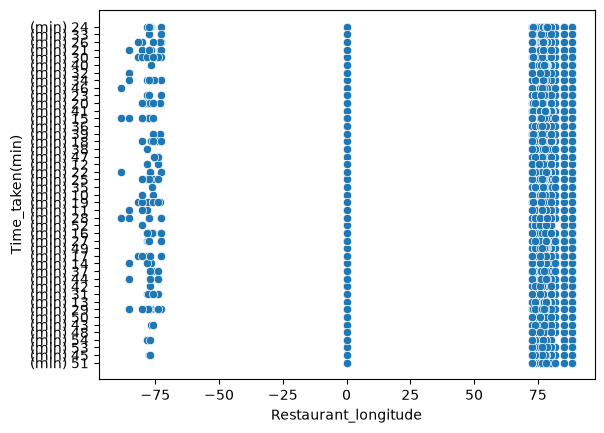

In [40]:
sns.scatterplot(x='Restaurant_longitude',y='Time_taken(min)',data=data)

<Axes: xlabel='Delivery_location_latitude', ylabel='Time_taken(min)'>

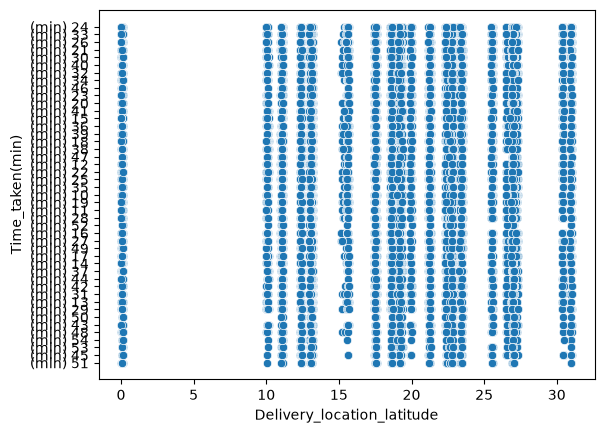

In [41]:
sns.scatterplot(x='Delivery_location_latitude',y='Time_taken(min)',data=data)

<Axes: xlabel='Weatherconditions', ylabel='count'>

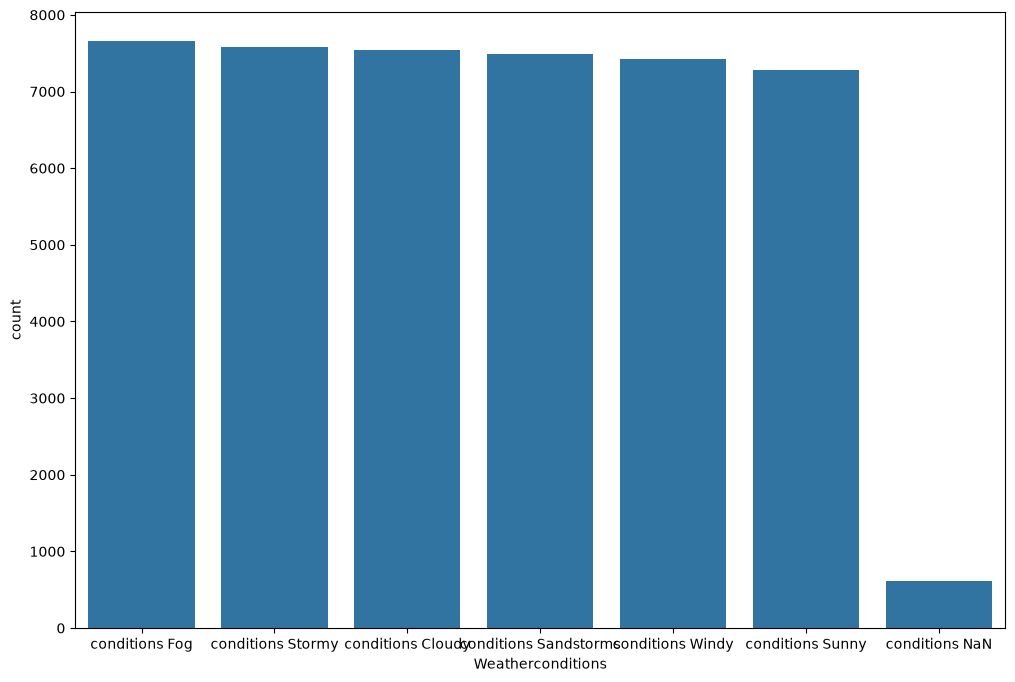

In [42]:
plt.figure(figsize=(12,8))
sns.countplot(x='Weatherconditions',order=data['Weatherconditions'].value_counts().index,data=data)

<Axes: xlabel='Vehicle_condition', ylabel='count'>

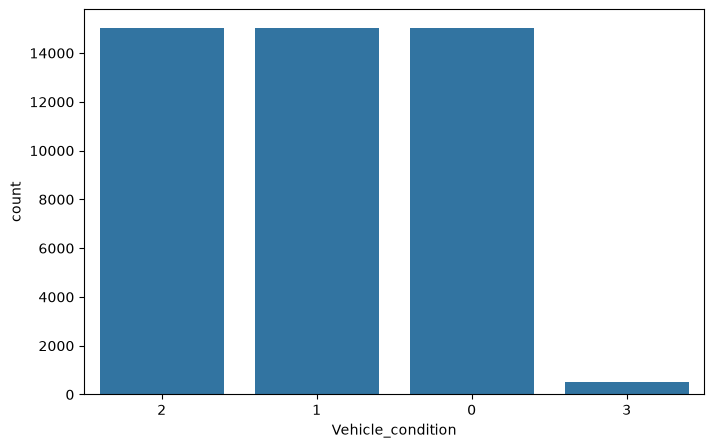

In [43]:
plt.figure(figsize=(8,5))
sns.countplot(x='Vehicle_condition',order=data['Vehicle_condition'].value_counts().index,data=data)

<Axes: xlabel='Type_of_order', ylabel='count'>

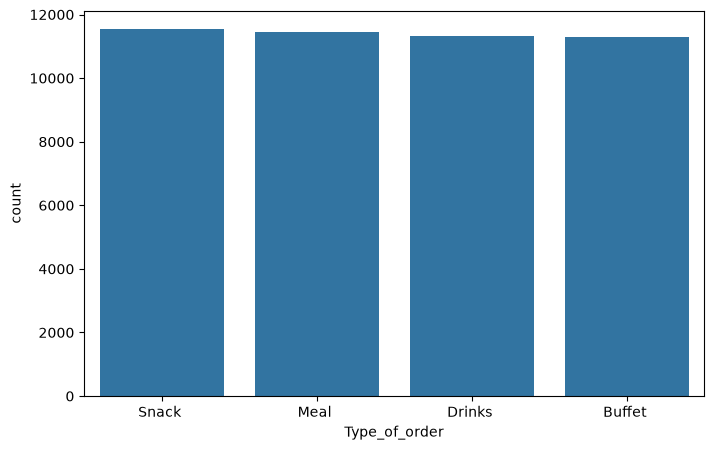

In [44]:
plt.figure(figsize=(8,5))
sns.countplot(x='Type_of_order',order=data['Type_of_order'].value_counts().index,data=data)

<Axes: xlabel='Type_of_vehicle', ylabel='count'>

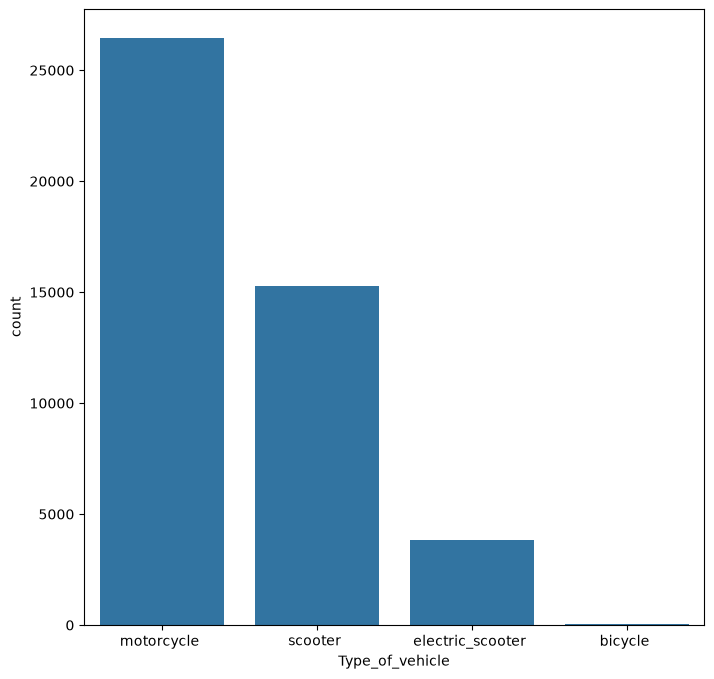

In [45]:
plt.figure(figsize=(8,8))
sns.countplot(x='Type_of_vehicle',order=data['Type_of_vehicle'].value_counts().index,data=data)

<Axes: xlabel='multiple_deliveries', ylabel='count'>

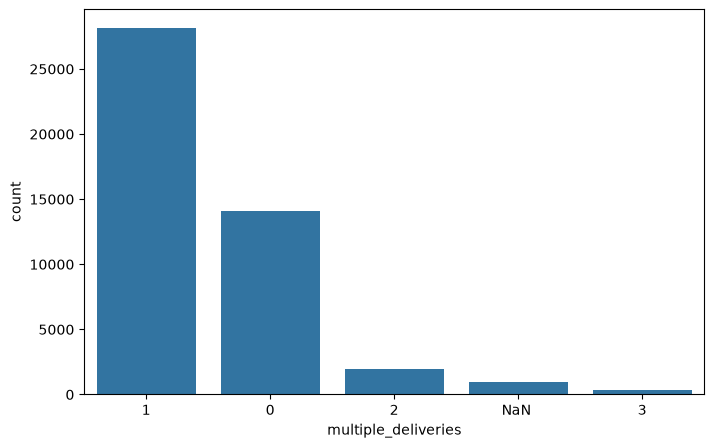

In [46]:
plt.figure(figsize=(8,5))
sns.countplot(x='multiple_deliveries',order=data['multiple_deliveries'].value_counts().index,data=data)

<Axes: xlabel='Festival', ylabel='count'>

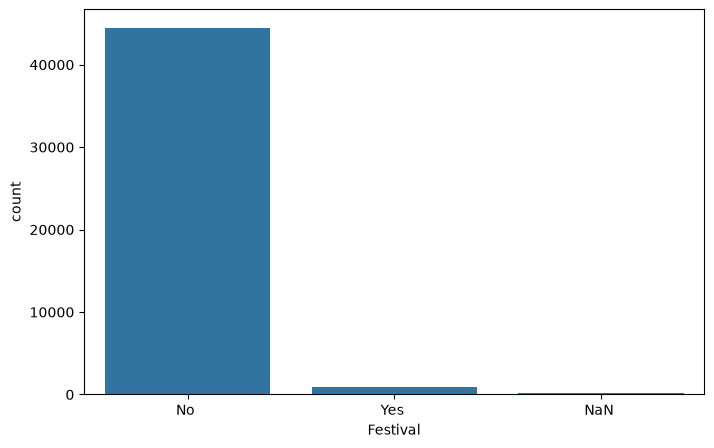

In [47]:
plt.figure(figsize=(8,5))
sns.countplot(x='Festival',order=data['Festival'].value_counts().index,data=data)

<Axes: xlabel='City', ylabel='count'>

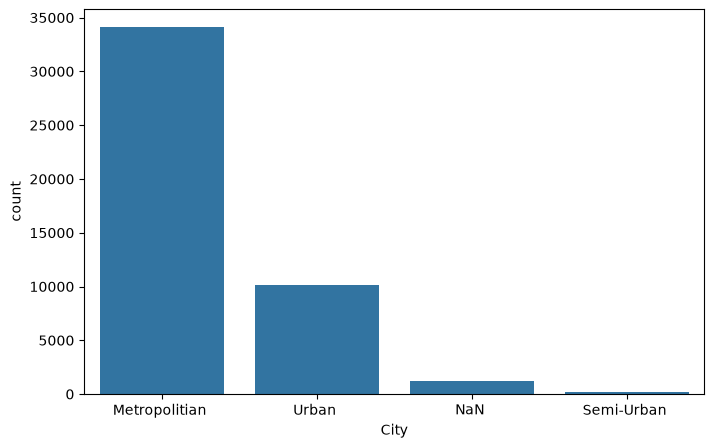

In [48]:
plt.figure(figsize=(8,5))
sns.countplot(x='City',order=data['City'].value_counts().index,data=data)

#### As seen in above plots data is not in cleaned format we have to clean the data of str columns . We will do this in Data_cleaning notebook and will return here to check skewness of data.

In [49]:
data = pd.read_csv(r'..\Datasets\Cleaned\Data_cleaned.csv')

In [50]:
numeric_columns = data.select_dtypes(include='number')
numeric_columns.skew()

Restaurant_latitude            0.128156
Restaurant_longitude           1.301492
Delivery_location_latitude     0.127860
Delivery_location_longitude    1.298622
Vehicle_condition              0.071853
multiple_deliveries            0.298735
Time_taken(min)                0.485951
distance_km                    0.465492
dtype: float64